### SUPPORT VECTOR MACHINES (REGRESSOR)

Import libraries and load files

In [5]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split


df = pd.read_csv("teen_phone_addiction_dataset.csv")

display(df.head())
print("Dataset shape:", df.shape)

,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6


Dataset shape: (3000, 25)


### define x and y and print feature columns

In [6]:
y = df["Addiction_Level"]
X = df.drop(columns=["Addiction_Level", "ID", "Name", "Location"])
print("Feature columns:", X.columns.tolist())


categorical_columns = X.select_dtypes(include=["object", "category"]).columns
numeric_columns = X.select_dtypes(exclude=["object", "category"]).columns

print("Categorical columns:", categorical_columns.tolist())
print("Numeric columns:", numeric_columns.tolist())


Feature columns: ['Age', 'Gender', 'School_Grade', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours']
Categorical columns: ['Gender', 'School_Grade', 'Phone_Usage_Purpose']
Numeric columns: ['Age', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Family_Communication', 'Weekend_Usage_Hours']


C:\Users\Nandini\AppData\Local\Temp\ipykernel_30040\298392880.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object", "category"]).columns


### train test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 2400
Test rows: 600


### Create the SVR model

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("svr", SVR(kernel="rbf"))
])

model.fit(X_train, y_train)
print("SVR model trained.")

SVR model trained.


- StandardScaler puts numeric features on comparable scales. This matters because SVR uses distances between examples.
- OneHotEncoder converts text categories, such as Gender or Phone_Usage_Purpose, into numeric features.
- Pipeline applies the preparation steps and then the SVR model in order.
- SVR(kernel="rbf") can model curved relationships between the features and the score.
- fit() learns from the training data.

### Predict and Evaluate 

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = mse ** 0.5
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.316
RMSE: 0.399
R²:   0.937


### Compare a few predictions with actual scores

In [10]:
comparison = pd.DataFrame({
    "Actual Addiction_Level": y_test,
    "Predicted Addiction_Level": predictions
})

display(comparison.head(10))

,Actual Addiction_Level,Predicted Addiction_Level
1801,10.0,9.602499
1190,10.0,9.866020
1817,10.0,9.996701
251,9.0,8.524678
2505,10.0,10.272865
1117,8.7,8.552135
1411,4.6,5.972674
2113,10.0,10.090732
408,10.0,9.402107
2579,10.0,9.835260


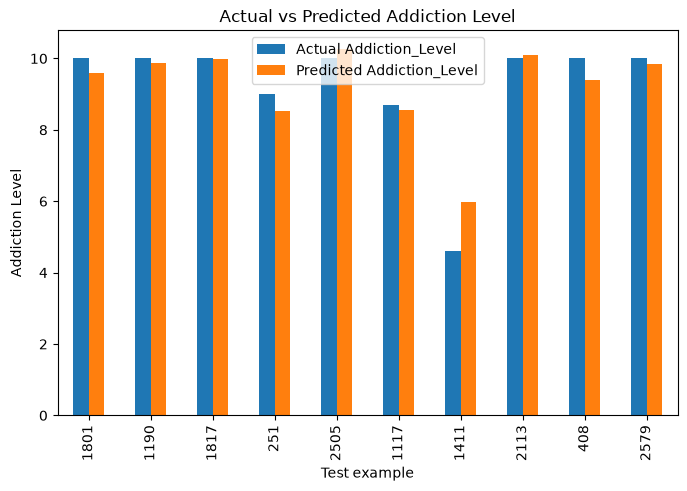

In [12]:
import matplotlib.pyplot as plt

comparison.head(10).plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Addiction Level")
plt.xlabel("Test example")
plt.ylabel("Addiction Level")
plt.show()